<a href="https://colab.research.google.com/github/nadeennaser-blip/Python-Data-Analysis-and-ML/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
%matplotlib inline
import pandas as pd   #قراءة البيانات وتجهيزها باستخدام pandas
import numpy as np  #اجراء العمليات الحسابية باستخدام numpy
import matplotlib.pyplot as plt  #عرض البيانات  بشكل بصري
import seaborn as sns    #عرض البيانات وفهم توزيعها
from sklearn.preprocessing import LabelEncoder, StandardScaler #استيراد الدالة الاولى لتحويل التصنيفات الى ارقام والدالة الثانية لتوحيد مقاييس البيانات العددية
from sklearn.feature_selection import SelectKBest, f_classif #اختيار الخصائص المناسبة الاكثر ارتباطا بالمتغير risk  # SelectKBest, f_classif باستخدام
#الاسطر هاي هدفها تحسين البيانات والنموذج
sns.set_style("whitegrid")  #بحدد شكل خلفية الرسومات وبضيف خطوط grid حتى تكون القراءى اسهل
plt.rcParams["figure.figsize"] = (10, 5)   #تحديد حجم الرسمة الارتفاع 10 والعرض 5
pd.set_option("display.width", 100) #عرض النصوص والجداول في مخرجات pandas خصوصا عند طباعتها
pd.set_option("display.max_columns", 20)  #بيعرض 20 عمود قبل ما يختصر العرض من عنده
print("All packages loaded successfully.")#رح يطبع كل البيانات

All packages loaded successfully.


In [9]:
import pandas as pd

DATA_PATH = "https://raw.githubusercontent.com/tatsath/fin-ml/master/Chapter%206%20-%20Sup.%20Learning%20-%20Classification%20models/german_credit_data.csv" #تحديد رابط الملف دون البحث عن الملف بالجهاز

dataset = pd.read_csv(DATA_PATH) #قراءة الملف وتخزينه في dataset in panadas
print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns") #بيعرض عدد الصفوف والاعندة عشان يعرض البيانات

dataset.head()#عرض اول خمس صفوف لفهم شكل البيانات

Dataset loaded: 1000 rows, 10 columns


,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [10]:
print("Shape (rows, columns):", dataset.shape) #عرض ابعاد البيانات من ناحية عدد الصفوف والاعمدة
dataset.dtypes #فحص البيانات لمعرفة نوع المعالجة للبيانات

Shape (rows, columns): (1000, 10)


,0
Age,int64
Sex,object
Job,int64
Housing,object
SavingAccounts,object
CheckingAccount,object
CreditAmount,int64
Duration,int64
Purpose,object
Risk,object


In [11]:
dataset.describe() #بيعرض الاحصاءات الوصفية للاعمدة الرقمية تلقائيا عشان نفهم القيم المتطرفة ونشوف التباين بين البيانات


,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [12]:
dataset.describe(exclude="number") #بيعرض الاحصاءات للبيانات لمعرفة اي الفئات انتشارا (ما عدا الارقام ما بيعرضها)

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [13]:
missing_counts = dataset.isna().sum() #فحص مجموع القيم المفقودة بكل عمود
print("Missing values per column:\n") #بعرض النتائج
print(missing_counts) #بيعرض القيم المفقودة بكل عمود
print(dataset["Risk"].value_counts())#بيعرض السجلات داخل كل فئة من المتغير اللي بدنا نتنبأ فيه
print() #بيطبع سطر فارغ اسهل للقراءة
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total") #رح يتم اختيار العمود اللي بدنا نتنبأ فيه ونحسب عدد كل فئة وتحيل العدد الى نسبة وتقريب النتيجة الى اقرب 3 منازل عشرية ثم تحويل النسبة لمئوية


Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64
Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


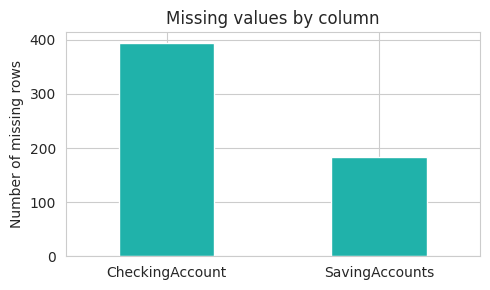

In [14]:

missing_counts = dataset.isna().sum() #بيقحص الفيمة المفقودة بكل عمود اذا كانت مفقودة رح يرجعها 1 واذا مش مفقودة 0 (هيك البايقون بتعامل مع البيانات اذا كانت صح او خطا )

missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False) #بيحسب اي عمود في اكثر من صفر قيم مفقودة وبيحتفظ بالاعمدة المفقودة وبيستبعد الاعمدة الغير مفقودة وبيرتب الاعداد من الاكبر للاصغر

plt.figure(figsize=(5, 3)) #بيحدد شكل الرسمة من ناحية ارتقاع وعرض
missing_counts.plot(kind="bar", color="#20B2AA", width=0.45)#بيرسم البيانات المفقودة وبيختار يرسمها عموديا وبيحدد اللون التركوازي بدقة  وعرض كل عمود

plt.title("Missing values by column") #اضافة عنوان للرسمة
plt.ylabel("Number of missing rows")#بسمي المحور العمودي وبيعرض الصفوف اللي بتمثل القيم المفقودة الموجودة بكل عمود
plt.xticks(rotation=0) #تعديل اتجاه اسماء الاعمدة والتحكم باتجاه النصوص على المحور الافقي عشان تكون سهلة القراءة
plt.tight_layout() #تعديل المسافات تلقائيا داخل الرسمة عشان تكون البيانات واضحة
plt.show() #هاد السطر بيطلب من مكتبة matplot عرض الرسم النهائي

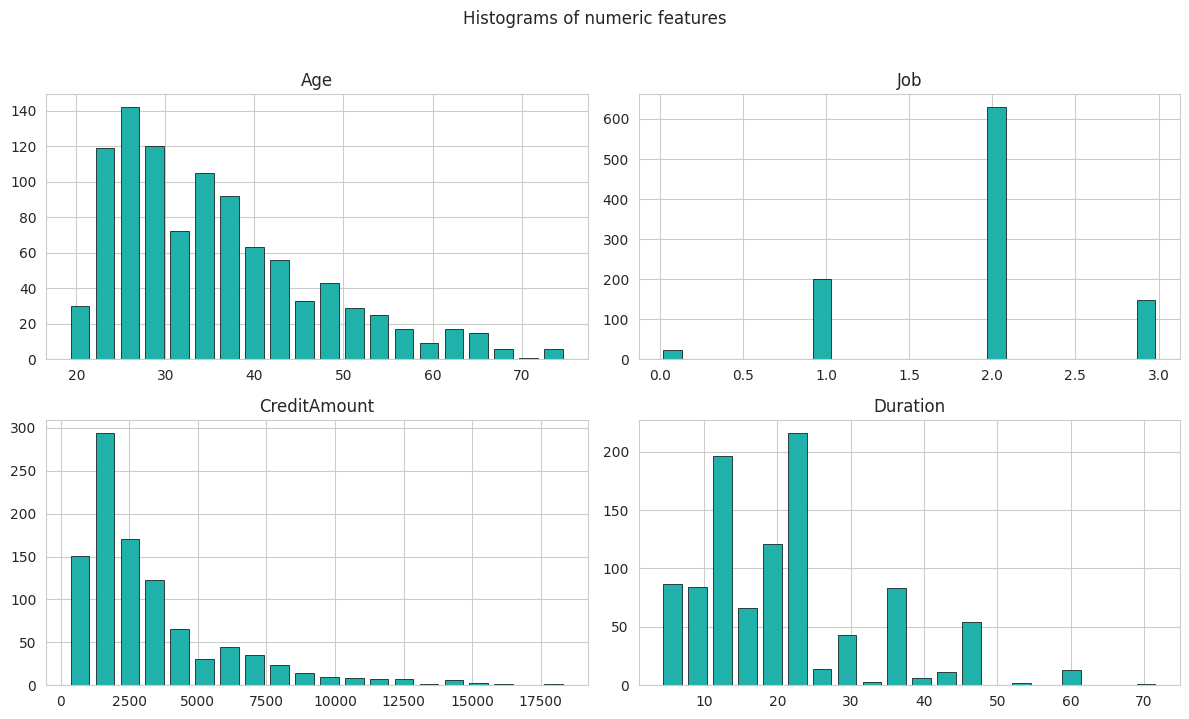

In [15]:

numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]
#حددنا الاعمدة اللي بدنا نحللها ورح يتم انشاء histogram لالها
dataset[numeric_cols].hist(
    figsize=(12, 7), #تحديد حجم مساحة البيانات
    bins=20,#بتم تقسيم المدى الى 20 فترة وبيحسب عدد القيم داخل كل فترة
    color="#20B2AA", #تحديد لون العمود
    edgecolor="black", #تحديد لون حدود الاعمدة
    linewidth=0.5, #سمك الاطار الخارجي للعمود
    rwidth=0.75 #بيحدد العرض النسبي لعمود histogram
)

plt.suptitle("Histograms of numeric features", y=1.02)#بيضيف عنوان رئيسي لكل الرسمات وموقع العنوان بالنسبة للرسمة
plt.tight_layout() #ضبط المسافات بين الرسومات وعناصرها تلقائيا حتى يقل التداخل بينها
plt.show() #عرض الرسومات النهائية على الشاشة


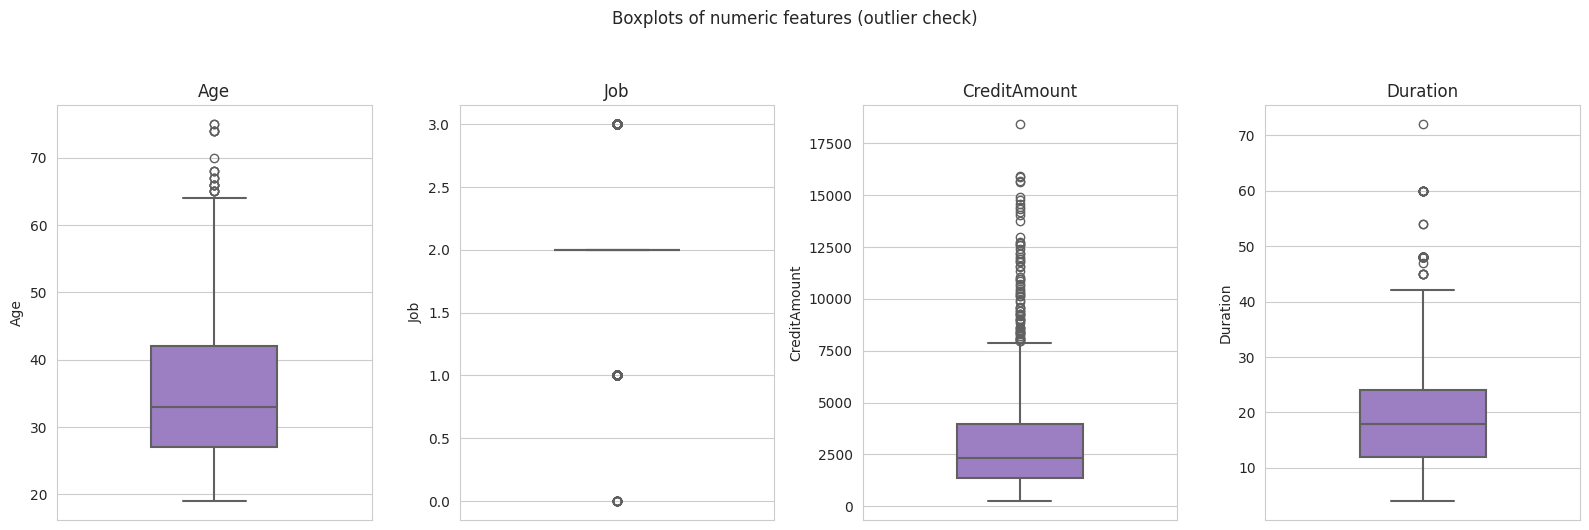

In [16]:

numeric_cols = ["Age", "Job", "CreditAmount", "Duration"] #بنحدد الاعمدة اللي بدنا نفحص توزيعها والقيم المتطرفة فيها
#list عشان نقدر نعمل لوب بدل ما انه كل عمود نحطله كود
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 5)) #إنشاء Figure وعدة رسومات فرعية
#4 Boxplots جنب بعض في صف واحد.
for ax, col in zip(axes, numeric_cols): #رح يمر على كل عمود ويرسمه في المكان المناسب
    sns.boxplot( #رسم Boxplot باستخدام Seaborn
        y=dataset[col], #استخدام قيم العمود الحالي على المحور العمودي
        ax=ax, # تحديد الرسم الفرعي المطلوب
        color="#9B72CF",
        width=0.4,
        linewidth=1.5
    )

    ax.set_title(col) #كتابة اسم العمود فوق السطر الخاص فيه

plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05) #اضافة عنوان واحد لكل الرسمات

plt.tight_layout()#بيحاول يعدل المسافات حتى ما تتداخل مع بعض
plt.show() #رح يتم عرض الرسمات


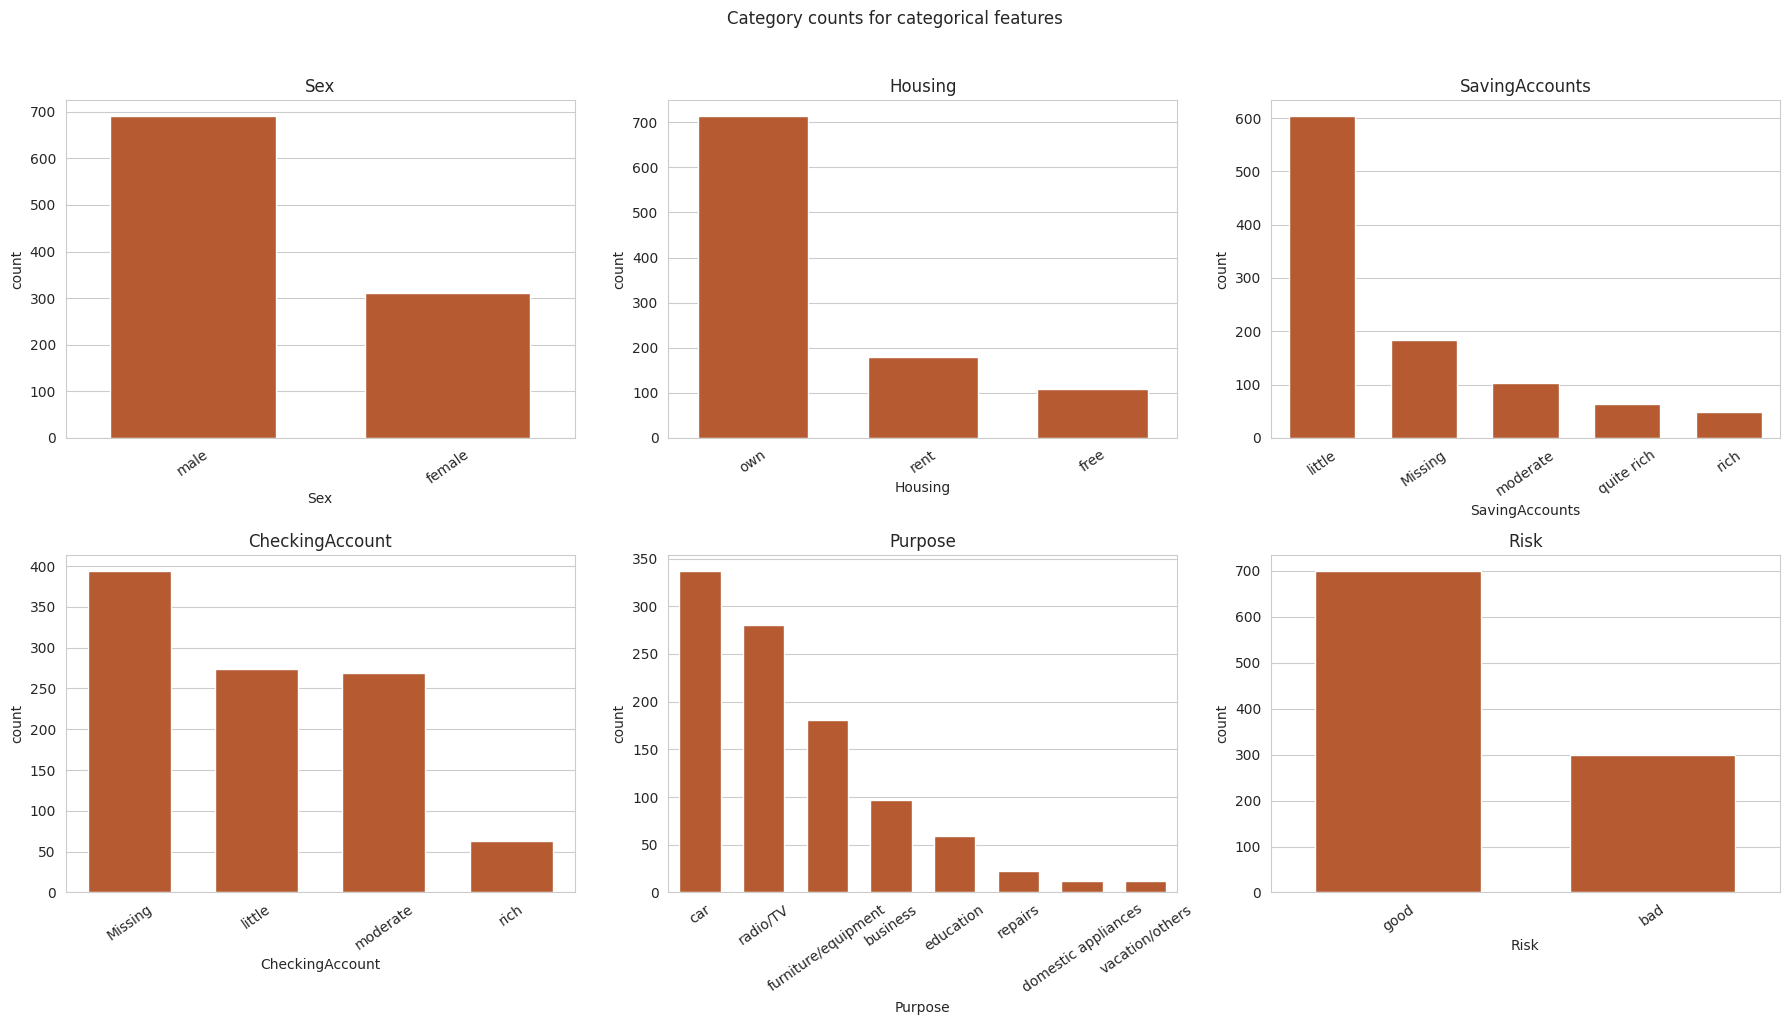

In [17]:
#دكتورة فكرة الاكواد الرسمية كلها تقريبا نفس الاسطر لهيك رح احكيلك شو فهمت من الكود
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):

    col_data = dataset[col].fillna("Missing")
    order = col_data.value_counts().index
    sns.countplot(
        x=col_data,
        order=order,
        ax=ax,
        color="#CC531B",
        width=0.65
    )

    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)

plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()
# تم اختيار 6 اعمدة فئوية ورسم عدد الحالات بكل فئة وترتيبها حسب الاكثر تكرارا ثم عرض الفئة المفقودة تظهر بشكل مستقل

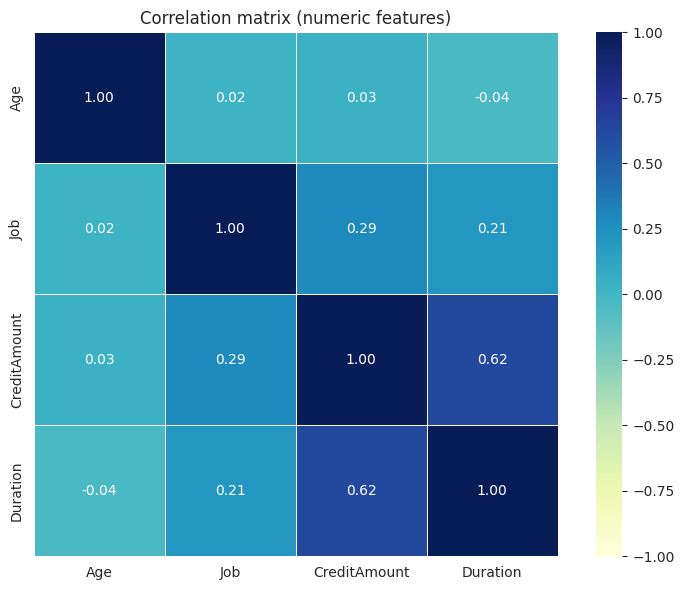

In [18]:

correlation = dataset[numeric_cols].corr() #بنختار الاعمدة الرقمية اللي سبق وحددناها وبينحسب معامل الارتباط بين كل عمود وعمود اخر وبتتخزن البيانات على شكل Correlation Matrix

plt.figure(figsize=(8, 6))

sns.heatmap( #رسم بياني بيستخدم الالوان لعرض قوة العلاقات بين متغيرين رقميين
    correlation,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5
)

plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()
#بتم تحديد العنوان لعرض البيانات على الرسم

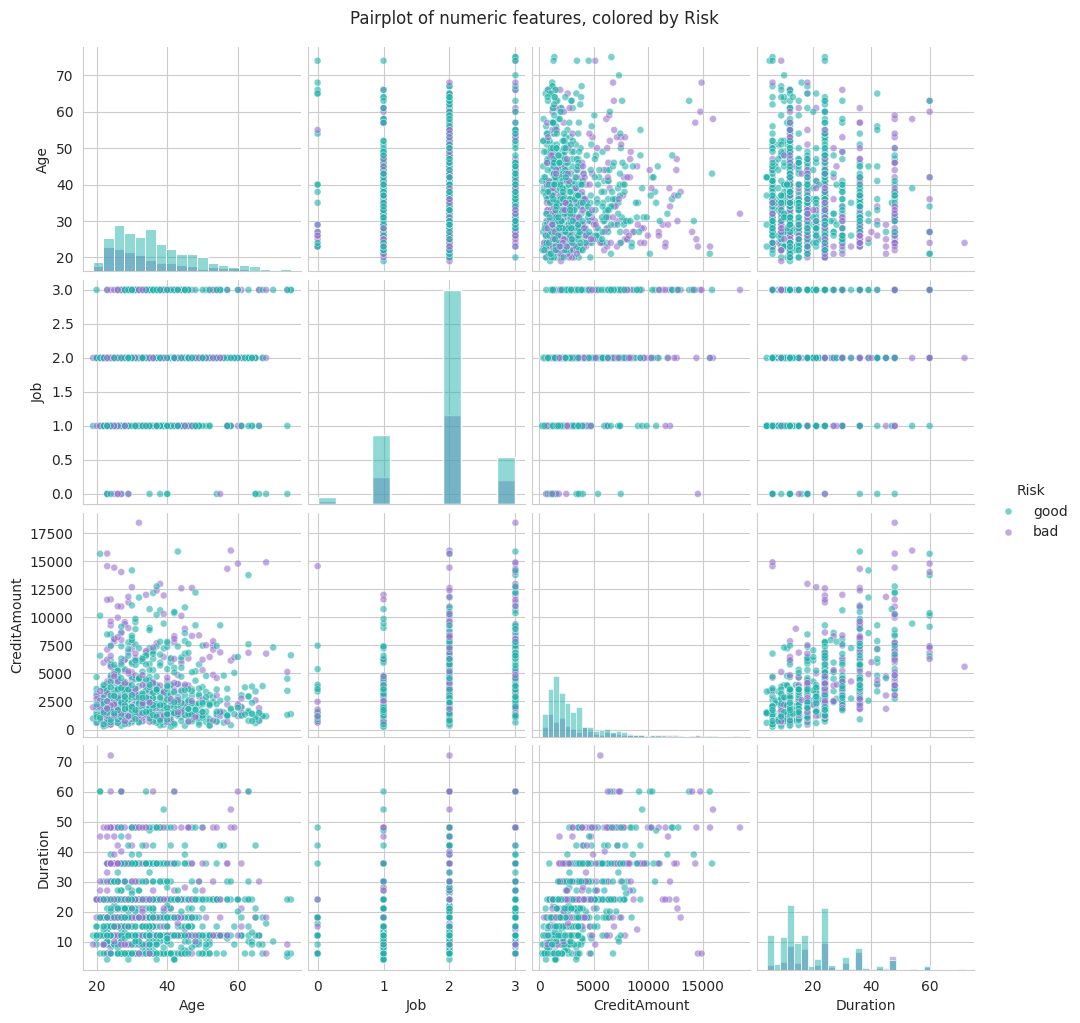

In [19]:
#دفه فهم العلاقات بين الخصائص ومدى تداخل فئات المخاطر قبل تدريب نموذج Machine Learning.
sns.pairplot(
    dataset,
    vars=numeric_cols,
    hue="Risk",
    palette={"good": "#20B2AA", "bad": "#9B72CF"},
    diag_kind="hist",
    height=2.5,
    plot_kws={"alpha": 0.6, "s": 25}
)

plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()


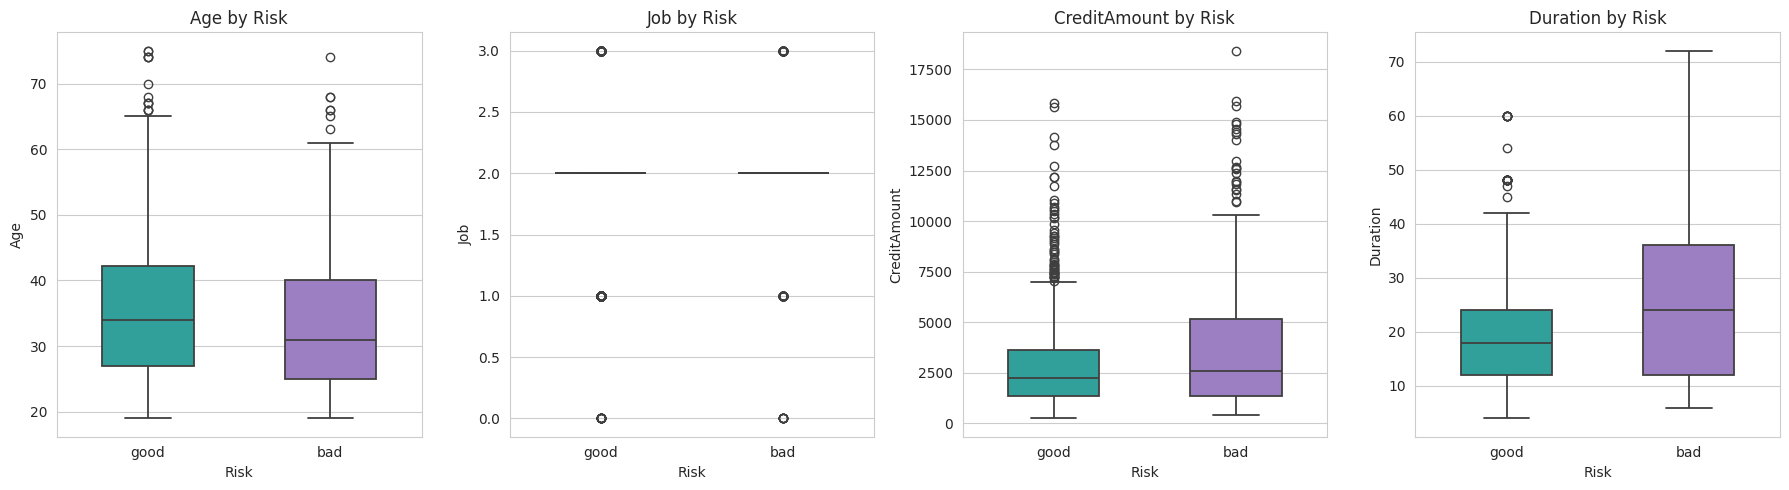

In [20]:
#Grouped Boxplots لمقارنة المتغيرات الرقمية بين فئتيgood وbad
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(18, 5))

for ax, col in zip(axes, numeric_cols):

    sns.boxplot(
        data=dataset,
        x="Risk", #على المحور الافقي
        y=col,#القيم الرقمية
        hue="Risk",
        palette={"good": "#20B2AA", "bad": "#9B72CF"},
        legend=False,
        ax=ax,
        width=0.5,
        linewidth=1.3
    )

    ax.set_title(f"{col} by Risk")
#هيك بقدر اقارن البيانات والاحظ القيم المتطرفة وافهم اي مخطار بتتعلق بالائئتمان
plt.tight_layout()
plt.show()

In [21]:

df_clean = dataset.copy() #عمل نسخة من البيانات المفقودة عشان نرجع الها وقت الحاجة

df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")

df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")
#SavingAccounts وCheckingAccount تم استبدالهم بكلمة none بدل ما احذف الصفوف
print("Remaining missing values:\n")
print(df_clean.isna().sum())#وهان تم فحص البيانات مرة اخرى حتى اتاكد انه ما ضل قيم مفقودة


Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


In [22]:

df_encoded = df_clean.copy() #نسخنا نسخة جديدة عشان نحول الفئات لارقام وبنفس الوقت احافظ على البيانات الاصلية عشان لما احتاجها ارجعلها
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]
encoders = {}

for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le

    print(f"{col:16s} -> {list(le.classes_)}")
#هان بيتم طباعة اسماء الفئات مش جدول التحول لما حولنا الفئات لرموز

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


In [23]:

scaler = StandardScaler() #StandardScaler لتوحيد مقياس المتغيرات الرقمية بحيث يصير المتوسط 0 والانحراف المعياري 1
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy() #نسخة من البيانات المرمزة
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale]) #تطبيق توحيد المقاييس على الاعمدة اللي تم اختيارها

print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):") # تمت مقارنة اول 3 صفوف قبل وبعد العملية لنشوف تغير القيم
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


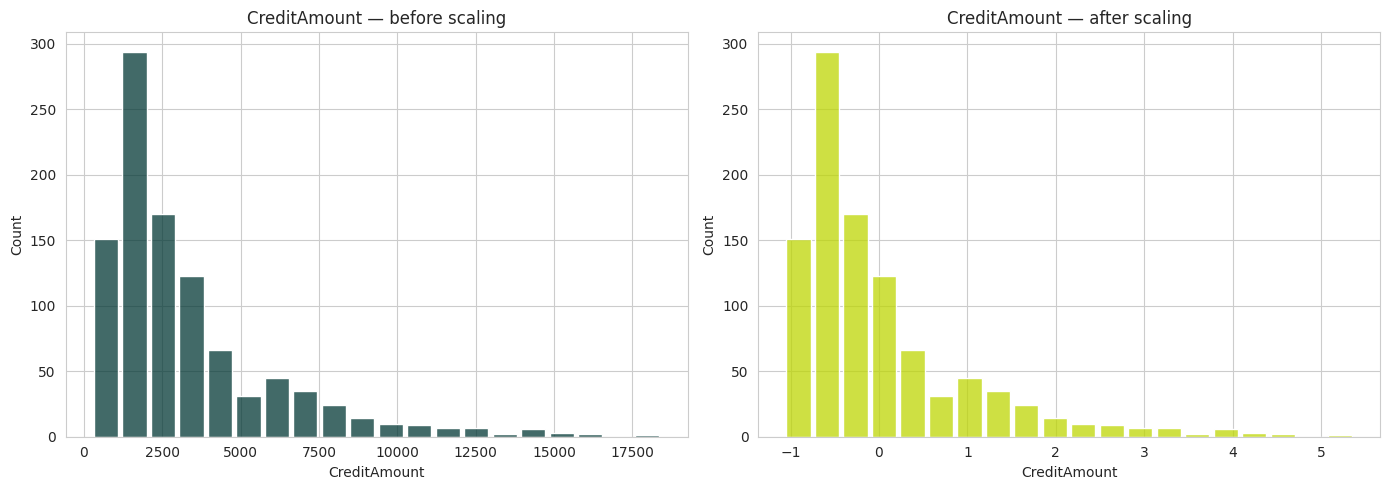

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5)) #رسمين جنب بعض بصف واحد قبل وبعد عملية scaling

sns.histplot( #عرض توزيع CreditAmount قبل Scaling.
    df_encoded["CreditAmount"],#عرض القيم الاصلية بتكون
    bins=20,
    ax=axes[0],
    color="#033835",
    shrink=0.85
)
axes[0].set_title("CreditAmount — before scaling")

sns.histplot(
    df_scaled["CreditAmount"], #القيم بعد تطبيق StandardScaler.
    bins=20,
    ax=axes[1],
    color="#BED604AB",
    shrink=0.85
)
axes[1].set_title("CreditAmount — after scaling")

plt.tight_layout()
plt.show() #التوزريع رح يضل نفسه بس المحور الافقي رح يتغير


In [25]:
X = df_scaled.drop(columns=["Risk"]) #input features
y = df_scaled["Risk"] #taget

selector = SelectKBest(score_func=f_classif, k="all")   #رح يشوف درجات كل الخصائص ويعرض افضل 3 لما يطبق الاختبار
selector.fit(X, y)#بتم تطبيق الاختبار على كل خاصية وعلاقتها بفئة الخطر

feature_scores = pd.DataFrame({
    "Feature": X.columns, #اسماء الخصائص
    "Score": selector.scores_ #الدرجات
}).sort_values("Score", ascending=False).reset_index(drop=True)#الترتيب من اعلى درجة الى اقل درجة لمعرفة اي الخصائص اكثر ارتباطا مع الخطر احصائيا

feature_scores

,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


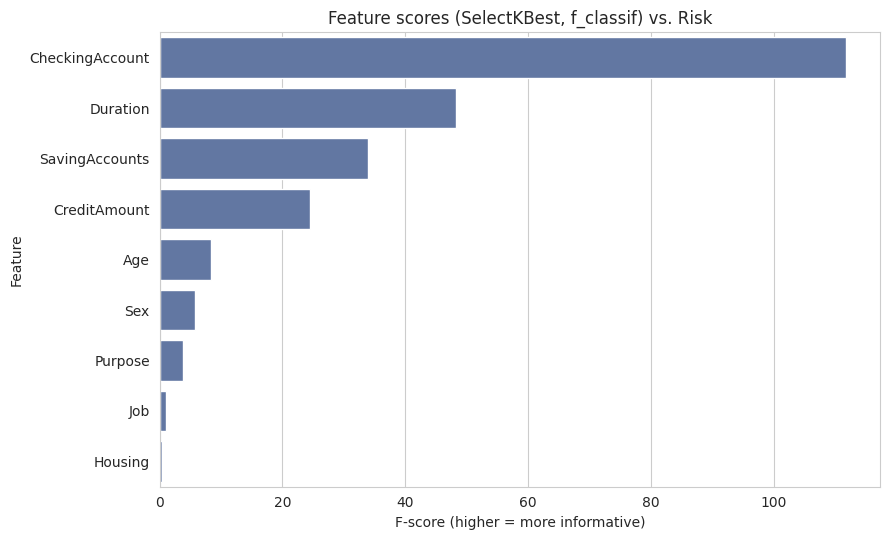

In [26]:
plt.figure(figsize=(9, 5.5))

sns.barplot(
    data=feature_scores, #تحويل feature score الى رسم بياني
    x="Score",
    y="Feature",
    color="#5874ACBD"
)

plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)") #كل ما كان الشريط اطول كان fscore اعلى

plt.tight_layout()
plt.show()